In [167]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import yfinance as yf 
import requests

In [168]:
nifty_index=yf.download("^NSEI",period="max",interval="1d")

[*********************100%***********************]  1 of 1 completed


In [169]:
print(nifty_index.shape)
print(nifty_index.tail(5))
print(nifty_index.head(5))


(4682, 5)
Price              Close          High           Low          Open  Volume
Ticker             ^NSEI         ^NSEI         ^NSEI         ^NSEI   ^NSEI
Date                                                                      
2026-10-12  22363.349609  22651.099609  22304.449219  22593.199219  258800
2026-10-13  22721.949219  22721.949219  22288.449219  22364.150391  308900
2026-10-14  22622.699219  22757.949219  22558.949219  22715.750000  333200
2026-10-15  22997.349609  23056.400391  22637.400391  22671.300781  370800
2026-10-16  23146.150391  23149.849609  22913.800781  23065.099609  391600
Price             Close         High          Low         Open Volume
Ticker            ^NSEI        ^NSEI        ^NSEI        ^NSEI  ^NSEI
Date                                                                 
2007-09-17  4494.649902  4549.049805  4482.850098  4518.450195      0
2007-09-18  4546.200195  4551.799805  4481.549805  4494.100098      0
2007-09-19  4732.350098  4739.000000  45

Data present for 4681 days and from 17-09-2007 to present, about 19 years

In [170]:
nifty_index.columns=nifty_index.columns.droplevel(level=1)

In [171]:
nifty_index = nifty_index[~nifty_index.index.get_level_values('Date').duplicated(keep='first')]
nifty_index.shape

(4682, 5)

In [172]:
nifty_index=nifty_index.drop(columns="Volume")
nifty_index.to_csv('nifty_index.csv')
print(nifty_index.columns)

Index(['Close', 'High', 'Low', 'Open'], dtype='str', name='Price')


No volume data for about 5 years, till 2013, best to drop those values

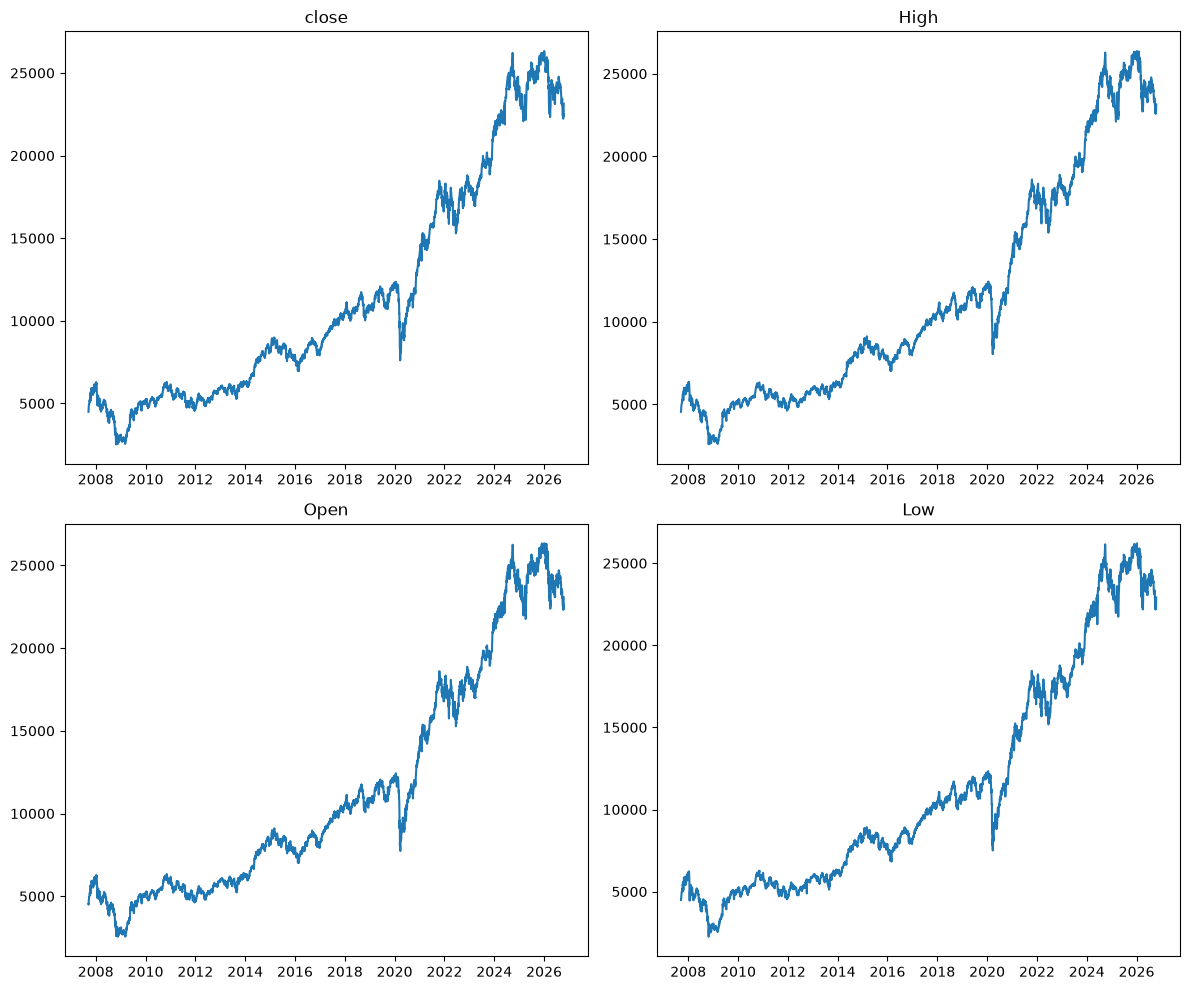

In [173]:

fig,axs=plt.subplots(2,2,figsize=(12,10))

axs[0,0].plot(nifty_index["Close"])
axs[0,0].set_title("close")

axs[0,1].plot(nifty_index["High"])
axs[0,1].set_title("High")

axs[1,0].plot(nifty_index["Open"])
axs[1,0].set_title("Open")

axs[1,1].plot(nifty_index["Low"])
axs[1,1].set_title("Low")

plt.tight_layout()



#### This data visualisation did not turn out to be helpful due to inability to see minor changes

count    4682.000000
mean        0.014224
std         0.012389
min         0.002465
25%         0.007543
50%         0.010819
75%         0.016392
max         0.193608
dtype: float64

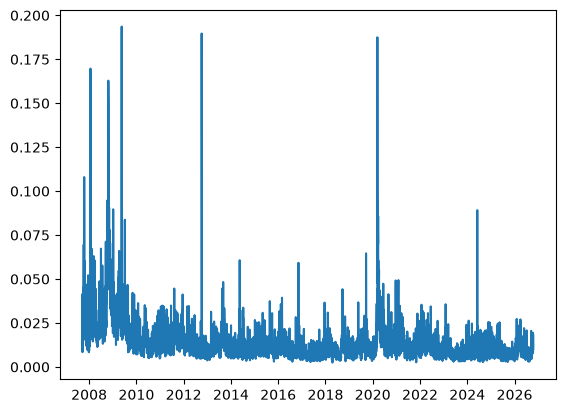

In [174]:
normalised_Range=(nifty_index["High"]-nifty_index["Low"])/(nifty_index["Low"])
plt.plot(normalised_Range)
# plt.ylim(0,800)
normalised_Range.describe()

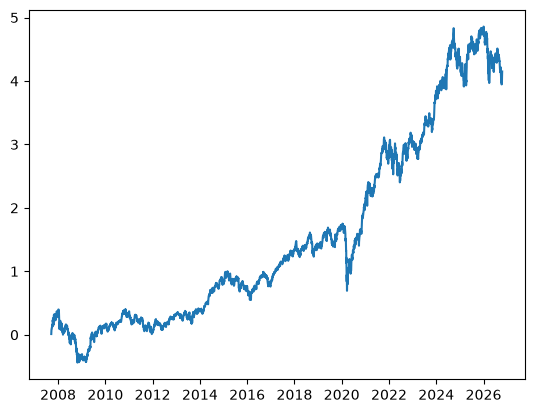

In [175]:
daily_returns = nifty_index["Close"].pct_change()
cummulative_returns=(1+daily_returns).cumprod()-1
plt.plot(cummulative_returns)

Lets Calculate Sharpe


0.22577241977182397


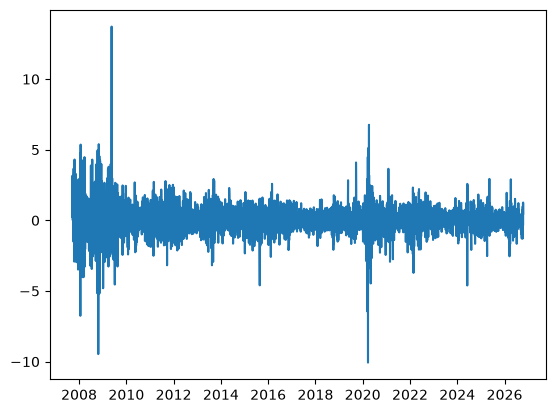

In [176]:
# Sharpe Signifies risk adjusted returns
# Sharpe = (average_return-riskfreereturn)/std_dev
risk_free_return=0.065
daily_risk_free_return=(1+risk_free_return)**(1/252) -1

excess_returns=daily_returns-daily_risk_free_return

average_return=excess_returns.mean()
standard_deviation = excess_returns.std()

daily_sharpe = excess_returns/standard_deviation

annualized_sharpe=(252**0.5)*average_return/standard_deviation
plt.plot(daily_sharpe)
print(annualized_sharpe)


We see a sudden rise in  2020s period, perhaps due to COVID imbalances

In [177]:
rolling_returns=daily_returns.rolling(window=252).mean().dropna()
rolling_returns

Date
2008-09-22    0.000010
2008-09-23   -0.000126
2008-09-24   -0.000255
2008-09-25   -0.000316
2008-09-26   -0.000512
                ...   
2026-10-12   -0.000380
2026-10-13   -0.000326
2026-10-14   -0.000373
2026-10-15   -0.000312
2026-10-16   -0.000276
Name: Close, Length: 4430, dtype: float64

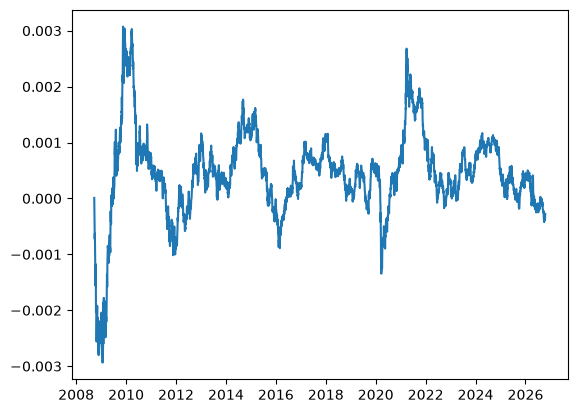

In [178]:
plt.plot(rolling_returns)

In [179]:
# Checking whether close is near high or low on daily basis
# we can use (high-close)/high-low
# gives a value in [0,1]

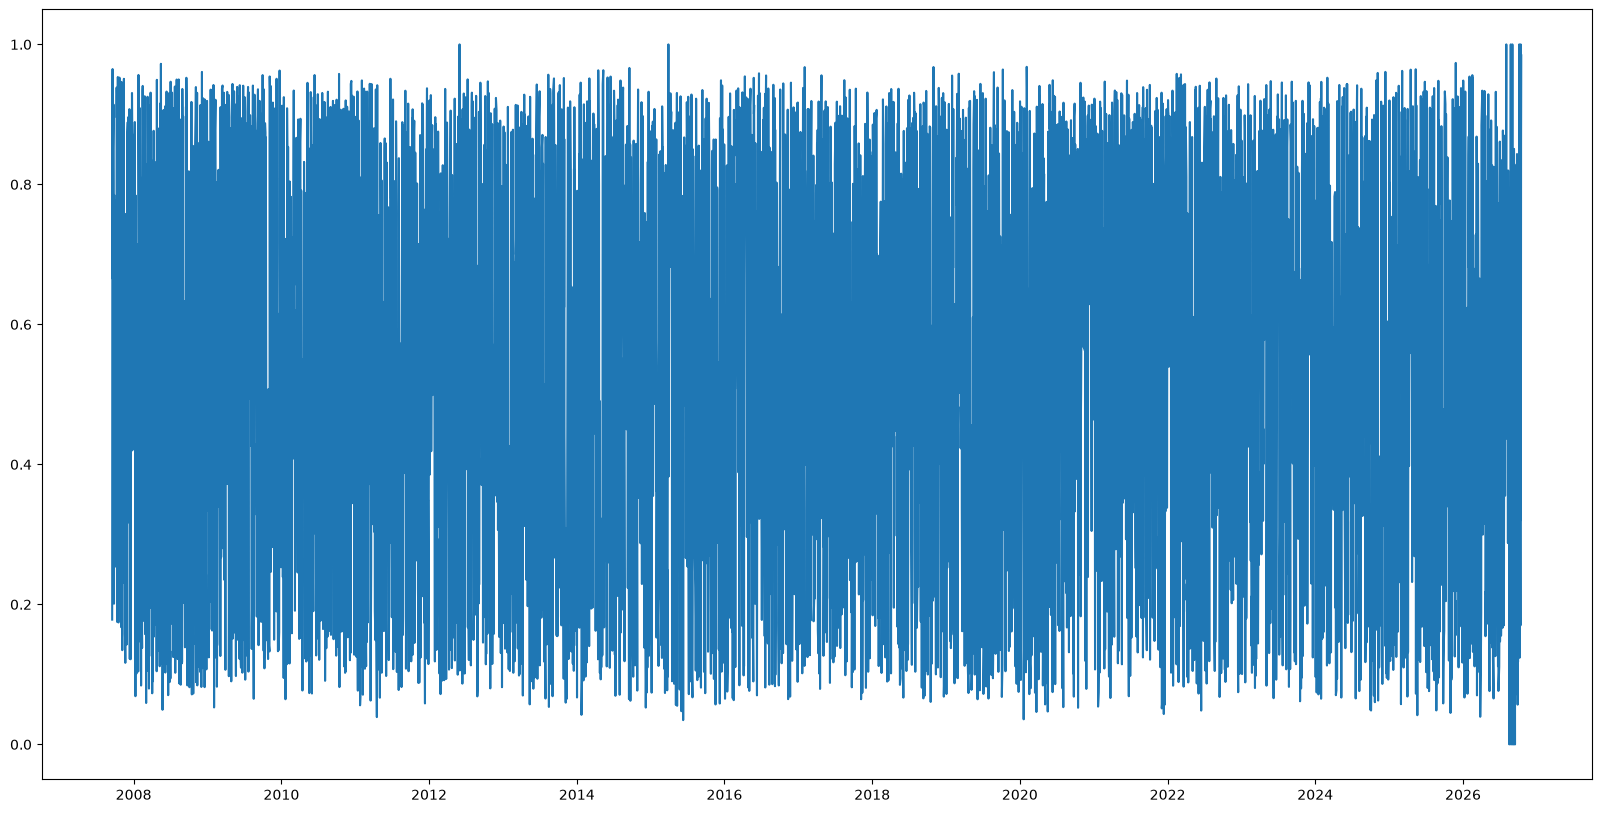

In [180]:
index=(nifty_index["Close"]-nifty_index["Low"])/(nifty_index["High"]-nifty_index["Low"])
plt.figure(figsize=(20,10))
plt.plot(index)

Quite VOlatile so lets just find out its rolling average

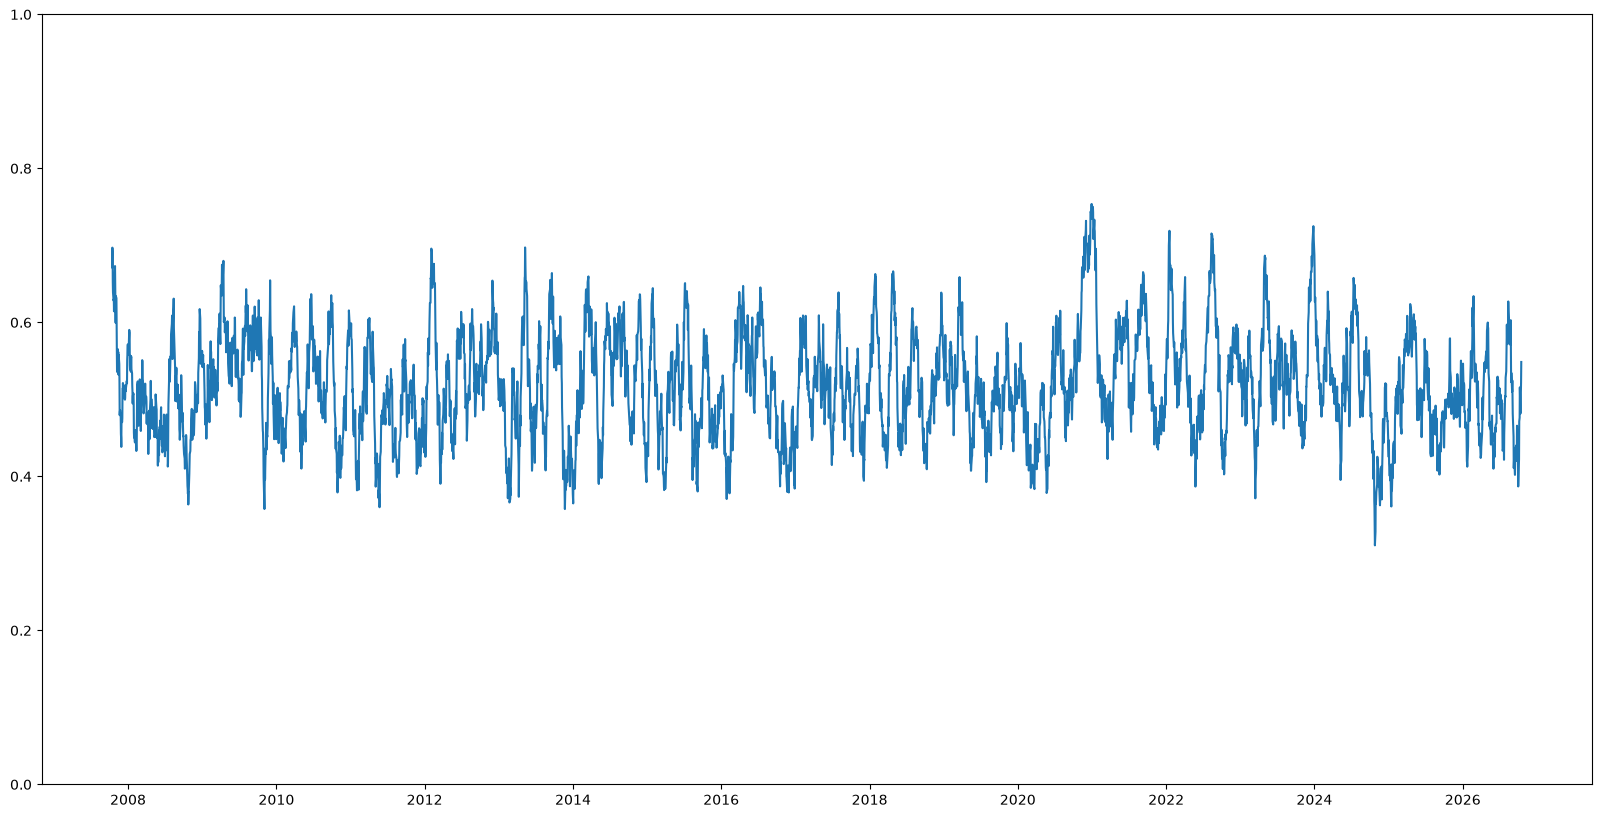

In [181]:
index.rolling(window=10).mean().dropna()
plt.figure(figsize=(20,10))
plt.ylim(0,1)
plt.plot(index.rolling(window=20).mean().dropna())
# Its almost averagely near 0.5


In [182]:
(daily_returns==0).sum()

np.int64(4)

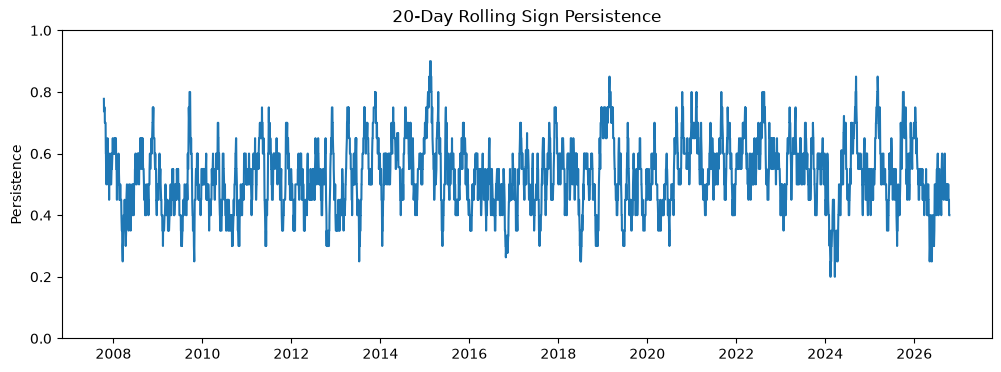

In [183]:
signs = np.sign(daily_returns)

same_sign = signs.eq(signs.shift(1))

valid_pairs = (
    signs.notna() & signs.shift(1).notna() &
    signs.ne(0) & signs.shift(1).ne(0)
)
window=20

matches = (same_sign & valid_pairs).rolling(window).sum()
valid_counts = valid_pairs.rolling(window).sum()

sign_persistence = matches / valid_counts.replace(0, np.nan)

plt.figure(figsize=(12, 4))
plt.plot(sign_persistence)
plt.title(f"{window}-Day Rolling Sign Persistence")
plt.ylabel("Persistence")
plt.ylim(0, 1)
plt.show()

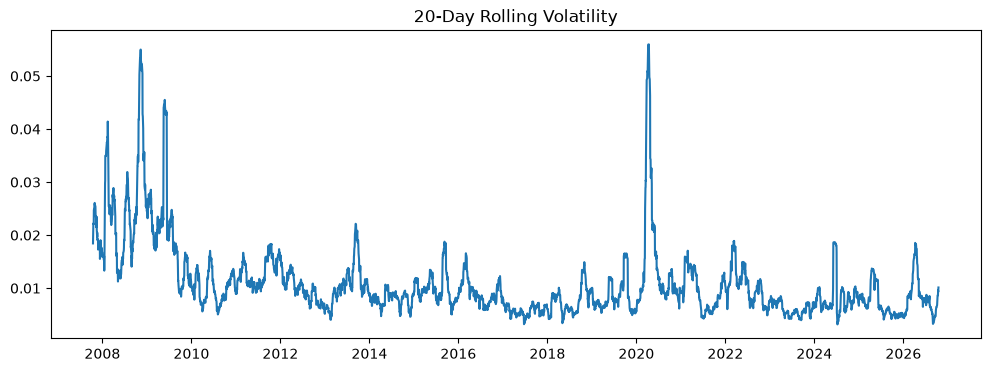

In [184]:
rolling_volatility = daily_returns.rolling(window=20).std()
plt.figure(figsize=(12, 4))

plt.plot(rolling_volatility)
plt.title("20-Day Rolling Volatility")
plt.show()

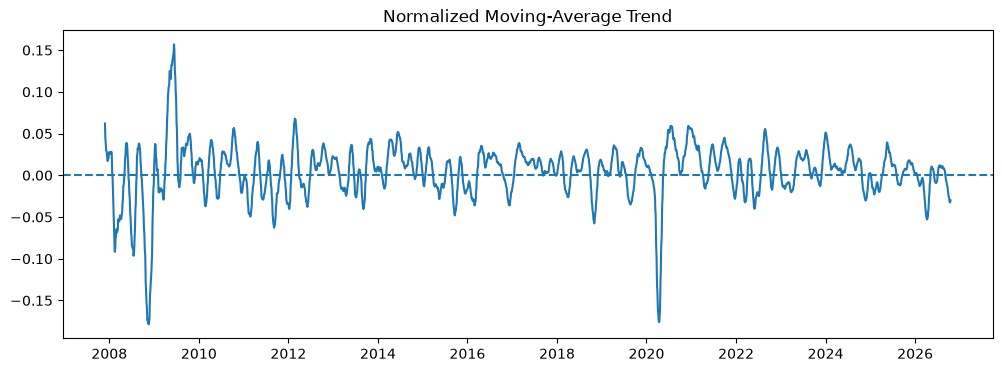

In [185]:
SMA_20 = nifty_index["Close"].rolling(window=20).mean()
SMA_50 = nifty_index["Close"].rolling(window=50).mean()

trend = (SMA_20 - SMA_50) / SMA_50

plt.figure(figsize=(12, 4))
plt.plot(trend)
plt.title("Normalized Moving-Average Trend")
plt.axhline(0, linestyle="--")
plt.show()

# current features
### Daily Returns
### 20 day Sign Persistance
### 20 day Rolling Volitilty
### Moving average Trend

In [186]:
features=pd.concat([daily_returns,sign_persistence,rolling_volatility,trend],axis=1)
features=features.dropna(axis=0)
features.columns=["daily_returns","sign_persistence","rolling_volatility","trend"]
features

,daily_returns,sign_persistence,rolling_volatility,trend
Date,,,,
2007-11-27,-0.005853,0.45,0.017276,0.062023
2007-11-28,-0.014145,0.50,0.017475,0.055358
2007-11-29,0.003035,0.50,0.017429,0.048744
2007-11-30,0.022743,0.55,0.018264,0.043876
2007-12-03,0.017743,0.60,0.018544,0.039046
...,...,...,...,...
2026-10-12,-0.006976,0.45,0.008648,-0.032535
2026-10-13,0.016035,0.45,0.009572,-0.032605
2026-10-14,-0.004368,0.40,0.009279,-0.031892


In [187]:
split_idx = int(len(features) * 0.8)
train_df=features.iloc[:split_idx]
test_df=features.iloc[split_idx:]

In [188]:
print(len(train_df))
print(len(test_df))


3706
927


In [189]:
means=train_df.mean()
means

daily_returns         0.000402
sign_persistence      0.529952
rolling_volatility    0.011618
trend                 0.004963
dtype: float64

In [190]:
standard_deviations=train_df.std()
standard_deviations

daily_returns         0.013739
sign_persistence      0.107522
rolling_volatility    0.007356
trend                 0.035222
dtype: float64

In [191]:
train_df=train_df-means
train_df=train_df/standard_deviations
train_df

,daily_returns,sign_persistence,rolling_volatility,trend
Date,,,,
2007-11-27,-0.455275,-0.743581,0.769154,1.620019
2007-11-28,-1.058761,-0.278561,0.796237,1.430789
2007-11-29,0.191674,-0.278561,0.790002,1.243011
2007-11-30,1.626112,0.186459,0.903506,1.104814
2007-12-03,1.262184,0.651479,0.941577,0.967679
...,...,...,...,...
2023-01-05,-0.234156,-0.743581,-0.532896,-0.225355
2023-01-06,-0.566055,-0.278561,-0.526761,-0.278562
2023-01-09,0.955982,-0.278561,-0.429331,-0.318966


In [192]:
test_df=test_df-means
test_df=test_df/standard_deviations
test_df.to_csv('test_df.csv')
test_df


,daily_returns,sign_persistence,rolling_volatility,trend
Date,,,,
2023-01-12,-0.181754,-0.278561,-0.484691,-0.457656
2023-01-13,0.371808,-0.743581,-0.485161,-0.478946
2023-01-16,-0.279530,-0.743581,-0.522820,-0.512919
2023-01-17,0.615231,-0.743581,-0.477979,-0.534109
2023-01-18,0.422499,-0.743581,-0.499678,-0.536985
...,...,...,...,...
2026-10-12,-0.536967,-0.743581,-0.403724,-1.064640
2026-10-13,1.137861,-0.743581,-0.278174,-1.066627
2026-10-14,-0.347159,-1.208601,-0.318005,-1.046385


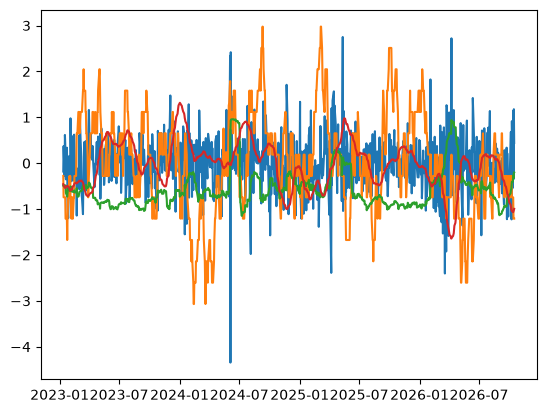

In [197]:
plt.plot(test_df)